# 2.4 – Advanced Feature Engineering Methods

A typical approach in Data Science is "featurization of the Universe". This means we could extract and engineer all the features possible for a given problem.

To give an example: In a time series problem, one could use cumulative sums, moving averages with variable window sizes, discrete state changes, average differences, etc. as features, which quickly becomes very large. Alternatively, data source can be so rich that already the raw extraction produces a vast amount of data.

In this case exploratory data analysis is challenging and we need to resort to alternative methods of visualizing and exploring the feature space.

One approach is to reduce the dimensionality of the feature space and poke around in this reduced feature space. A basic technique well-suited for this problem is the Principal Component Analysis which tries to find the directions of most variation in your data set. 

## Principal Component Analysis (PCA)
Visualizing 2 or 3-dimensional data is not that challenging. However, even the Iris dataset is 4-dimensional. We can use PCA to reduce that 4-dimensional data into 2 or 3 dimensions so that you can plot and hopefully understand the data better.

Reducing the size of the feature space sounds helpful, but might cause different problems. Therefore, always beware of two key challenges for dimensionality reduction:
1. We want to **retain as much of the information as possible**. If we blindly remove information, the world becomes easier, but we cannot apply machine learning anymore.
2. We want to **keep the information interpretable**. If we randomly convolute information, it might yield alright results, but as humans we cannot make sense of these results anymore.

The Iris dataset consists of 50 samples from each of three species of Iris (Iris setosa, Iris virginica and Iris versicolor). Four features were measured from each sample: the length and the width of the sepals and petals, in centimeters.

![](./data/3_2_iris.png)

### Data Preparation

In [ ]:
from pathlib import Path

candidate_paths = [
  parent / "data" / "2_4_iris.csv"
  for parent in (Path.cwd(), *Path.cwd().parents)
]

data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find data/2_4_iris.csv in the repository.")

print(f"Loading: {data_path.resolve()}")

In [2]:
import pandas as pd

df = pd.read_csv(data_path)

df.head()

,sepal length,sepal width,petal length,petal width,target
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


#### **TASK: Data Prepration**
PCA is effected by scale so you need to scale the features in your data before applying PCA. 

Use StandardScaler to help you standardize the dataset’s features (mean = 0 and variance = 1).

In [3]:
from sklearn.preprocessing import StandardScaler

features = ['sepal length', 'sepal width', 'petal length', 'petal width']

# Separating out the features
x = df.loc[:, features]

# Separating out the target
y = df.loc[:,['target']]

# Standardizing the features
x_scaled = StandardScaler().fit_transform(x)

### Dimensionality Reduction
The original data has 4 columns (sepal length, sepal width, petal length, and petal width). We want to project the original data which is 4-dimensional into 2 dimensions. After dimensionality reduction, there usually isn’t a particular meaning assigned to each principal component. The new components are just the two main dimensions of variation.

To that, we apply a [PCA](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) for two dimensions ("components") on the standardized data set.

In [4]:
from sklearn.decomposition import PCA

# select parameters for PCA: 2 components, fixed random state for reproducibility
pca = PCA(n_components=2, random_state=42)
# fit and transform the data, i.e., project it onto the 2 principal components
principalComponents = pca.fit_transform(x_scaled)
# create a DataFrame with the principal components
df_pc = pd.DataFrame(data = principalComponents, columns = ['PC 1', 'PC 2'])

Now we are able to plot the two principal components:

In [5]:
df_pc['target'] = df['target']
df_pc.head()

,PC 1,PC 2,target
0,-2.264542,0.505704,Iris-setosa
1,-2.086426,-0.655405,Iris-setosa
2,-2.367950,-0.318477,Iris-setosa
3,-2.304197,-0.575368,Iris-setosa
4,-2.388777,0.674767,Iris-setosa


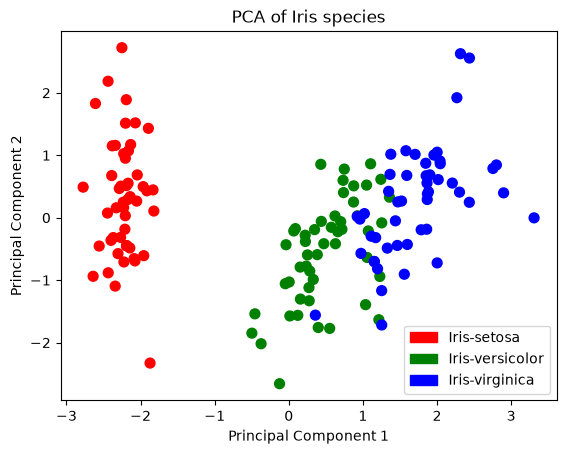

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# map target names to colors
colors = {'Iris-setosa': 'red', 'Iris-versicolor': 'green', 'Iris-virginica': 'blue'}
df_pc['target2'] = df_pc['target'].map(colors)

# create a scatter plot of the two principal components
plt.scatter(df_pc['PC 1'], df_pc['PC 2'], c=df_pc['target2'], s=50)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Iris species')

# create legend items
patches = [mpatches.Patch(color=c, label=l) for l, c in colors.items()]
plt.legend(handles=patches)
plt.show()

#### **TASK: Dimensionality Reduction to 2D**

How would you describe interpret the plot?
Can you interpret the principal components?

*Description*

- PC1 separates `Iris-setosa` clearly from the other two species
- PC2 seems to be similarly distributed across all flower species
- ``Iris-versicolor`` and ``Iris-virginica`` are not as distinguishable

*Interpretation*

We can only guess what the principal components might represent. But it seems to represent size and shape somehow.

### Explained Variance and Loadings

The **explained variance** tells you how much information (variance) can be attributed to each of the principal components. This is important because you lose some of the variance (information) when you convert a 4-dimensional space to a 2-dimensional space. By using the attribute `explained_variance_ratio_`, you can see that the first principal component contains 72.77% of the variance and the second principal component contains 23.03% of the variance. Together, the two components contain 95.80% of the information.

In [7]:
# explained variance ratio
pca.explained_variance_ratio_

array([0.72770452, 0.23030523])

In [8]:
explained_variance = pca.explained_variance_ratio_[0] + pca.explained_variance_ratio_[1]
# explained_variance in percent
print("Total variance explained: " + str(explained_variance.round(4)*100) + "%")

Total variance explained: 95.8%


**Loadings** show how strongly each original feature contributes to a principal component. Mathematically speaking, they are the coefficients of the linear combinations that define the PCs.
- absolute loading = influence of feature on PC
- positive or negative value = direction of that relationship

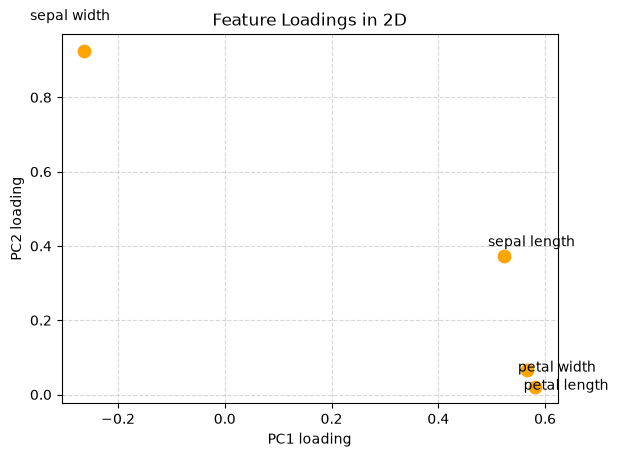

In [9]:
# get feature names from all dataset columns except 'target'
feature_names = df.columns[:-1]  

# loadings are the contribution of each feature to each PC, shape: (n_features, n_components)
loadings = pca.components_.T

# plot loadings
x_loadings, y_loadings = loadings[:, 0], loadings[:, 1]
plt.scatter(x_loadings, y_loadings, color='orange', s=80)
for i, name in enumerate(feature_names):
  plt.text(x_loadings[i]*1.1, y_loadings[i]*1.1, name, ha='center', va='center')
plt.title("Feature Loadings in 2D")
plt.xlabel("PC1 loading")
plt.ylabel("PC2 loading")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

The loading plot visualizes the contribution of each original feature to the principal components PC1 and PC2. Each point represents one feature.
- `sepal width` seems to be pretty similar to the original feature because it has almost a loading of 1 for PC2.
- `petal width` and `petal length` are combined into PC1 and share similar loadings.
- `sepal length` is somewhere in between and slightly loads onto both, PC1 and PC2.

Together with the species plot, we can say that `petal width`, `petal length`, and `sepal length` separate `Iris-setosa` from the other species. However, all species have similar distributions of `sepal width`.

#### **TASK: Explained Variance and Interpretation**

1. Compute a principal component analysis for one dimension
2. Try to interpret the single principal component

In [10]:
# compute PCA for one dimension
pca1 = PCA(n_components=1)
# fit and transform the data to one dimension
principalComponents1 = pca1.fit_transform(x_scaled)
# create a DataFrame with the principal component
df_pc1 = pd.DataFrame(data = principalComponents1, columns = ['PC 1'])
# explained variance ratio for one component
pca1.explained_variance_ratio_.sum()

np.float64(0.7277045209380133)

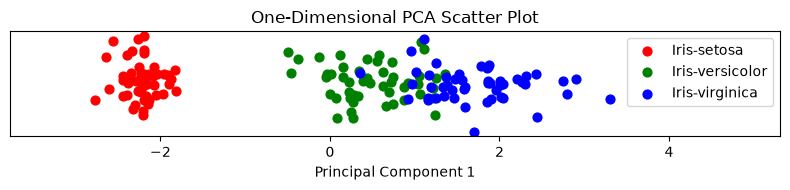

In [ ]:
import numpy as np
# map target names to colors
colors = {'Iris-setosa': 'red', 'Iris-versicolor': 'green', 'Iris-virginica': 'blue'}
df_pc1['target'] = df['target']
df_pc1['target2'] = df_pc['target'].map(colors)

# plot one-dimensional PCA scatter plot
plt.figure(figsize=(8,2))
for species, color in colors.items():
  mask = df_pc1['target'] == species
  # small vertical jitter to prevent overlap
  jitter = np.random.normal(0, 0.02, mask.sum())
  plt.scatter(df_pc1.loc[mask, 'PC 1'], jitter, c=color, label=species, s=40)

plt.yticks([])  # hide vertical axis
plt.xlim(df_pc1['PC 1'].min()-1, df_pc1['PC 1'].max()+2) # make room for legend
plt.xlabel("Principal Component 1")
plt.title("One-Dimensional PCA Scatter Plot")
plt.legend()
plt.tight_layout()
plt.show()

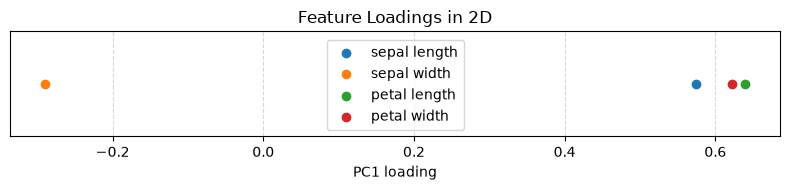

In [12]:
# get feature names from all dataset columns except 'target'
feature_names = df.columns[:-1]  
# compute loadings for one component
loadings = pca1.components_.T

# plot loadings
plt.figure(figsize=(8,2))
for i, name in enumerate(feature_names):
  plt.scatter(loadings[i, 0]*1.1, 0,label=name)
plt.title("Feature Loadings in 2D")
plt.xlabel("PC1 loading")
plt.yticks([])  # hide vertical axis
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

*Interpretation*

PC1 from the 1D-PCA is primarily constructed from `petal width`, `petal length`, and `sepal length`. Therefore, it is similar to PC1 from the 2D-PCA